# 03 - Feature Selection

Used car price prediction, step 3 of the project. Each step has its own notebook:

- 01 - data loading, exploration, cleaning, and preprocessing
- 02 - exploratory data analysis
- **03 - feature selection (this notebook)**

**Goal:** decide which input features the model should use.

**Approach:** we only drop a feature if it clearly adds nothing. We do not aim for a short list, because removing a feature that quietly helps would make the model worse. Three kinds of evidence are combined:

1. Correlations between the features, to find features that overlap.
2. Feature importance from a Random Forest (built-in importance and permutation importance).
3. A cross-validated test: retrain without the feature and see if the score drops.

As in notebook 02, everything here uses the **training data only**. The test set stays unseen.

Note: this notebook takes a few minutes to run, because of the cross-validation in section 6.

## 1. Setup

In [1]:
# Import the libraries used in this notebook
import os
import json
import time
import warnings
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.model_selection import train_test_split, KFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score

warnings.filterwarnings("ignore")      # keep the output readable
sns.set_theme(style="whitegrid")
os.makedirs("figures", exist_ok=True)  # folder for the charts

# Print the library versions (we pin them in requirements.txt later)
print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("matplotlib:", matplotlib.__version__)
print("seaborn:", sns.__version__)
print("scikit-learn:", sklearn.__version__)

pandas: 2.2.3
numpy: 2.4.6
matplotlib: 3.10.0
seaborn: 0.13.2
scikit-learn: 1.6.1


In [2]:
# A small helper: tidy the layout, save the chart as a PNG file, then show it
def save_fig(name):
    plt.tight_layout()
    plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 2. Load the cleaned data and recreate the training set

In [3]:
# Load the cleaned data saved by notebook 01.
# First try to read it straight from the GitHub repo. If the repo is private, or the file
# has not been pushed yet, fall back to uploading the file by hand (a file picker appears).
DATA_URL = "https://raw.githubusercontent.com/MirajAdhikari/used-car-price-prediction/main/data/processed/cardekho_cleaned.csv"

try:
    clean = pd.read_csv(DATA_URL)
    print("Loaded the cleaned data from GitHub.")
except Exception:
    from google.colab import files
    uploaded = files.upload()                       # choose cardekho_cleaned.csv
    clean = pd.read_csv(next(iter(uploaded)))
    print("Loaded the cleaned data from the uploaded file.")

print("Shape (rows, columns):", clean.shape)


Loaded the cleaned data from GitHub.
Shape (rows, columns): (15240, 13)


In [4]:
# The same feature lists and the same 80/20 split as in notebooks 01 and 02
target = "selling_price"
numeric_features = ["vehicle_age", "km_driven", "mileage", "engine",
                    "max_power", "seats", "km_per_year"]
categorical_features = ["brand", "model", "seller_type", "fuel_type", "transmission_type"]
all_features = numeric_features + categorical_features

X = clean[all_features]
y = clean[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training rows:", len(X_train), "| Test rows (not used here):", len(X_test))

Training rows: 12192 | Test rows (not used here): 3048


## 3. Overlap between features

If two features carry almost the same information, we may not need both. We check the correlation between the numeric features.

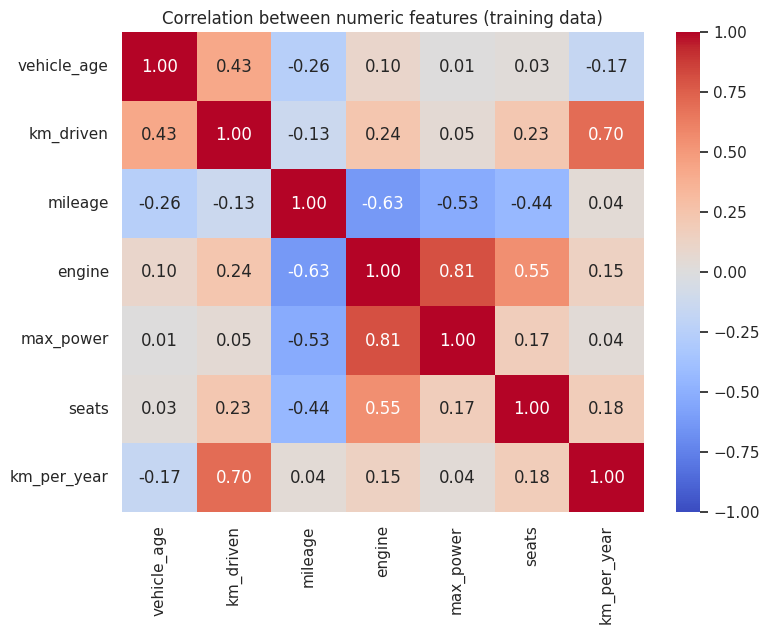

Strongly related pairs:
  km_driven and km_per_year: 0.7
  mileage and engine: -0.63
  engine and max_power: 0.81


In [5]:
# Correlation between the numeric features (training data only)
feature_corr = X_train[numeric_features].corr()

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(feature_corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation between numeric features (training data)")
save_fig("08_feature_correlation")

# List every pair of features with a strong correlation (0.6 or more, positive or negative)
pairs = []
for i, a in enumerate(numeric_features):
    for b in numeric_features[i + 1:]:
        r = feature_corr.loc[a, b]
        if abs(r) >= 0.6:
            pairs.append((a, b, round(r, 2)))
print("Strongly related pairs:")
for a, b, r in pairs:
    print(f"  {a} and {b}: {r}")

## 4. Feature importance with a Random Forest

We train a Random Forest and measure how much each feature matters. Two measures are used:

- **Built-in importance:** how much each feature is used by the trees to split the data. It is known to favor features with many distinct values or categories (like `model`), so we do not rely on it alone.
- **Permutation importance:** shuffle one feature's values on data the model has not seen, and measure how much the score drops. A big drop means the model depends on that feature. This is fairer, and it treats each original column as one feature (it does not split `brand` into many one-hot columns).

To measure importance on unseen data without touching the test set, we hold out part of the **training** data as a validation set (80% fit, 20% validation).

We run the analysis twice, with log price and with raw price as the target, because we have not decided yet which one to use for modeling (that comes in the modeling notebook). A feature is only trusted as useless if it looks useless under both.

In [6]:
# Hold out 20% of the training data for measuring importance
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42)
print("Fit rows:", len(X_fit), "| Validation rows:", len(X_val))

# The two targets we compare. np.log turns prices into log prices.
targets = {
    "log price": np.log,
    "raw price": lambda values: values,
}

# Build a Random Forest pipeline that uses only the chosen features.
# Numeric columns are standardized and text columns are one-hot encoded, as in notebook 01.
# n_estimators=40 and max_features=0.33 keep the runtime short. Here we only compare
# features with each other, so a smaller forest is good enough.
def make_model(features):
    num_cols = [f for f in numeric_features if f in features]
    cat_cols = [f for f in categorical_features if f in features]
    preprocessor = ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ])
    forest = RandomForestRegressor(n_estimators=40, max_features=0.33,
                                   random_state=42, n_jobs=-1)
    return Pipeline([("pre", preprocessor), ("rf", forest)])

Fit rows: 9753 | Validation rows: 2439


In [7]:
# Train one model per target and measure the importance of every feature
start = time.time()
perm_results = {}      # permutation importance (mean and spread) for each target
builtin_results = {}   # built-in importance, added up per original column
val_scores = {}

for name, transform in targets.items():
    model = make_model(all_features)
    model.fit(X_fit, transform(y_fit))
    val_scores[name] = r2_score(transform(y_val), model.predict(X_val))

    # Permutation importance on the validation set (5 shuffles per feature)
    perm = permutation_importance(model, X_val, transform(y_val),
                                  n_repeats=5, random_state=42, n_jobs=-1)
    perm_results[name] = pd.DataFrame(
        {"mean": perm.importances_mean, "std": perm.importances_std}, index=X_val.columns
    )

    # Built-in importance: the forest gives one number per encoded column,
    # so we add them back up to the original feature they came from.
    encoded_names = model.named_steps["pre"].get_feature_names_out()
    encoded_importance = model.named_steps["rf"].feature_importances_
    grouped = {}
    for feature in all_features:
        grouped[feature] = sum(
            imp for col, imp in zip(encoded_names, encoded_importance)
            if col == f"num__{feature}" or col.startswith(f"cat__{feature}_")
        )
    builtin_results[name] = pd.Series(grouped)

print("Validation R2:", {k: round(v, 3) for k, v in val_scores.items()})
print("Time taken:", round(time.time() - start), "seconds")

Validation R2: {'log price': 0.939, 'raw price': 0.93}
Time taken: 14 seconds


In [8]:
# One table with all three measures, sorted by permutation importance (log price)
importance_table = pd.DataFrame({
    "built-in (log price)": builtin_results["log price"],
    "permutation (log price)": perm_results["log price"]["mean"],
    "permutation (raw price)": perm_results["raw price"]["mean"],
}).sort_values("permutation (log price)", ascending=False)

importance_table.round(4)

,built-in (log price),permutation (log price),permutation (raw price)
max_power,0.3747,0.4810,0.6103
vehicle_age,0.1751,0.3258,0.1917
engine,0.1395,0.0797,0.1132
transmission_type,0.0955,0.0403,0.0666
km_driven,0.0430,0.0225,0.0696
fuel_type,0.0332,0.0158,0.0088
model,0.0454,0.0093,0.0170
seller_type,0.0061,0.0052,0.0008
brand,0.0250,0.0049,0.0151
mileage,0.0319,0.0039,0.0124


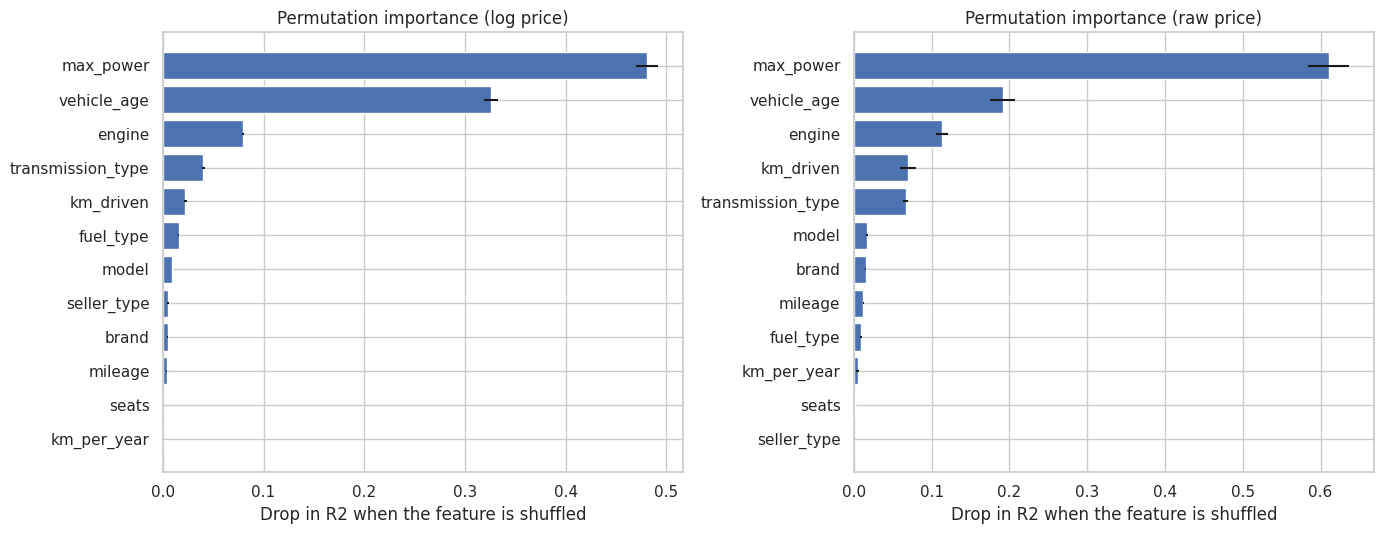

In [9]:
# Chart: permutation importance for both targets, with the spread over the 5 shuffles
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=False)

for ax, name in zip(axes, ["log price", "raw price"]):
    result = perm_results[name].sort_values("mean")
    ax.barh(result.index, result["mean"], xerr=result["std"], color="#4C72B0")
    ax.set_title(f"Permutation importance ({name})")
    ax.set_xlabel("Drop in R2 when the feature is shuffled")

save_fig("09_feature_importance")

## 5. Which features are candidates for removal?

A feature becomes a **candidate** only if shuffling it barely hurts the model under **both** targets: permutation importance below 0.01 for log price and for raw price. Everything else clearly matters, so it stays.

In [10]:
# Candidates: low importance under both targets
low_log = perm_results["log price"]["mean"] < 0.01
low_raw = perm_results["raw price"]["mean"] < 0.01
candidates = [f for f in all_features if low_log[f] and low_raw[f]]

print("Candidates for removal:", candidates)

Candidates for removal: ['seats', 'km_per_year', 'seller_type']


## 6. Cross-validated drop test

Low importance is not proof that a feature is useless, because overlapping features can share the credit. So for each candidate we do a direct test: retrain the model without it and compare scores with 5-fold cross-validation on the training data.

**Our rule:** a candidate is dropped only if removing it lowers the cross-validated R2 by less than **0.002** under both log price and raw price. This threshold is a judgement call: it is a very small change, about the size of random variation between runs. A feature that causes a bigger loss stays.

In [11]:
# 5-fold cross-validation on the training data
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

def cv_scores(features, transform):
    """R2 on each of the 5 validation folds, for a model that uses `features`."""
    scores = []
    for fit_idx, val_idx in kfold.split(X_train):
        model = make_model(features)
        model.fit(X_train.iloc[fit_idx][features], transform(y_train.iloc[fit_idx]))
        predictions = model.predict(X_train.iloc[val_idx][features])
        scores.append(r2_score(transform(y_train.iloc[val_idx]), predictions))
    return np.array(scores)

start = time.time()
rows = []
for name, transform in targets.items():
    baseline = cv_scores(all_features, transform)           # all features
    for feature in candidates:
        without = [f for f in all_features if f != feature]
        scores = cv_scores(without, transform)               # all features except one
        rows.append({
            "feature": feature,
            "target": name,
            "R2 with all features": baseline.mean(),
            "R2 without it": scores.mean(),
            "loss": (baseline - scores).mean(),               # positive = the model got worse
        })
    print("Finished", name, "after", round(time.time() - start), "seconds")

drop_test = pd.DataFrame(rows)
drop_test.round(4)

Finished log price after 68 seconds
Finished raw price after 135 seconds


,feature,target,R2 with all features,R2 without it,loss
0,seats,log price,0.9337,0.9337,0.0001
1,km_per_year,log price,0.9337,0.9332,0.0006
2,seller_type,log price,0.9337,0.9305,0.0033
3,seats,raw price,0.9250,0.9182,0.0067
4,km_per_year,raw price,0.9250,0.9262,-0.0012
5,seller_type,raw price,0.9250,0.9213,0.0037


In [12]:
# Apply the rule: drop a candidate only if the loss is below 0.002 under both targets
max_loss = drop_test.groupby("feature")["loss"].max()
to_drop = [f for f in candidates if max_loss[f] < 0.002]
to_keep = [f for f in candidates if f not in to_drop]

print("Dropped (clearly adds nothing):", to_drop)
print("Kept (removing it hurts):", to_keep)

Dropped (clearly adds nothing): ['km_per_year']
Kept (removing it hurts): ['seats', 'seller_type']


## 7. Findings

Numbers below are from the training data and are rounded.

**Overlap between features**
- Engine and max power are strongly related (about 0.81), and mileage falls as engine size rises (about -0.63). `km_per_year` is calculated from `km_driven` and the vehicle age, so it is related to `km_driven` (about 0.70) by construction.

**Importance**
- `max_power` and `vehicle_age` are the two most important features under both targets. For log price, shuffling `max_power` drops R2 by about 0.47 and shuffling `vehicle_age` by about 0.32. For raw price the figures are about 0.61 and 0.19.
- `engine`, `transmission_type`, and `km_driven` come next. `engine` still matters even though it overlaps with `max_power`, so we keep it.
- The built-in importance ranks `model` and `brand` higher than permutation importance does. This is the bias toward features with many categories that we expected, which is why we do not use built-in importance alone.

**Candidates and the drop test**
- Three features had low importance under both targets: `seats`, `km_per_year`, and `seller_type`.
- `km_per_year`: removing it changes the score by almost nothing (a loss of about 0.0004 for log price, and the raw-price score even rises slightly). It adds nothing, so it is **dropped**. It was also the feature most affected by the extreme-usage rows we decided to keep.
- `seats`: almost no loss under log price, but a clear loss of about 0.007 under raw price. So it does help, and it is **kept**.
- `seller_type`: a small but consistent loss under both targets (about 0.0025 and 0.0037). It is **kept**. This one is borderline, because 0.0025 is close to our 0.002 threshold. The threshold is a judgement call.

**What was not removed, and why**
- Engine, max power, and mileage overlap, but none of them is useless. Removing a feature whose information is partly shared can still lose information, so we keep all of them. The models will cope with overlapping features (tree models do so by design, and Linear Regression is only mildly affected here).

**Limits of this analysis**
- Forests with 40 trees were used to keep the runtime short, so differences of about 0.001 are within random variation. That is why we only dropped a feature whose removal had essentially no effect.
- Feature selection was done with a Random Forest. A different model could rank features slightly differently. If the modeling results look odd, we can come back to this decision.

**Result:** 11 features are kept and only `km_per_year` is dropped. The app is not affected: it still asks for the same inputs and auto-fills engine, max power, mileage, and seats.


## 8. Final feature list

The final list is saved as `selected_features.json` so the modeling notebooks use exactly the same features.

In [13]:
# Final features = all features minus the dropped ones
selected_numeric = [f for f in numeric_features if f not in to_drop]
selected_categorical = [f for f in categorical_features if f not in to_drop]

print("Selected numeric features:    ", selected_numeric)
print("Selected categorical features:", selected_categorical)
print("Dropped features:             ", to_drop)

# Save the lists for the next notebooks
selection = {
    "numeric_features": selected_numeric,
    "categorical_features": selected_categorical,
    "dropped_features": to_drop,
}
with open("selected_features.json", "w") as file:
    json.dump(selection, file, indent=2)
print("Saved selected_features.json")

Selected numeric features:     ['vehicle_age', 'km_driven', 'mileage', 'engine', 'max_power', 'seats']
Selected categorical features: ['brand', 'model', 'seller_type', 'fuel_type', 'transmission_type']
Dropped features:              ['km_per_year']
Saved selected_features.json


In [14]:
# In Colab, download the JSON file and the charts.
# Put selected_features.json in data/processed/ and the PNG files in reports/figures/.
import shutil

try:
    from google.colab import files
    files.download("selected_features.json")
    shutil.make_archive("feature_selection_figures", "zip", "figures")
    files.download("feature_selection_figures.zip")
except ImportError:
    print("Not running in Colab, so the files stay in the current folder.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9. Summary

- Checked overlap between features, measured importance in two ways under two targets, and tested each weak feature with cross-validation.
- Only features that clearly add nothing were removed (see the findings above). The final list is saved in `selected_features.json`.

**Next:** notebook 04, model development, which uses these features.